In [1]:
import logging
import os
import sys
from io import BytesIO
import pandas as pd
import requests
from datetime import date, timedelta, datetime
from collections import Counter
import numpy as np
import json
from astroquery.vizier import Vizier
import astropy.units as u
from astropy.io import fits
from astropy.coordinates import SkyCoord
from tqdm import tqdm
import time
from astropy.table import Table, Column, vstack, join
import re
from astropy.time import Time
from glob import glob
from multiprocessing import Pool

from desispec.io import read_spectra
from desispec.coaddition import coadd_cameras
from desiutil.depend import Dependencies
from scipy.ndimage import gaussian_filter1d

In [2]:
import sys
import numpy as np

sys.path.insert(0, "/pscratch/sd/z/zixinq/timedomain/desitrip/py")
from desitrip.preproc import rebin_flux, rescale_flux

In [3]:
def load_metadata_table(file_path):
    """Load the FASTSPEC table from a FITS file."""
    with fits.open(file_path) as hdul:
        return Table(hdul['METADATA'].data)

In [ ]:
loa_path = "/global/cfs/cdirs/desi/vac/dr2/fastspecfit/loa/v1.0/catalogs"
fastspec_files = np.sort(glob(os.path.join(loa_path, "*.fits")))
loa_metadata = vstack([load_metadata_table(os.path.join(loa_path, i)) for i in fastspec_files])

In [5]:
import os
import numpy as np
from tqdm.auto import tqdm


loa_targetid = np.asarray(loa_metadata["TARGETID"]).astype(np.int64)
loa_spectype = np.asarray(loa_metadata["SPECTYPE"]).astype(str)

# Check whether the same TARGETID has conflicting SPECTYPE values
targetid_to_spectype = {}

for tid, spectype in zip(loa_targetid, loa_spectype):
    if tid in targetid_to_spectype:
        if targetid_to_spectype[tid] != spectype:
            print(
                f"Warning: TARGETID {tid} has multiple SPECTYPE values: "
                f"{targetid_to_spectype[tid]} and {spectype}"
            )
    else:
        targetid_to_spectype[tid] = spectype

print(f"LOA lookup contains {len(targetid_to_spectype):,} unique TARGETIDs")

LOA lookup contains 37,032,439 unique TARGETIDs


In [ ]:
import numpy as np
from collections import defaultdict

spectypes_by_targetid = defaultdict(list)

for tid, spectype in zip(
    np.asarray(loa_metadata["TARGETID"]).astype(np.int64),
    np.asarray(loa_metadata["SPECTYPE"]).astype(str),
):
    spectype = spectype.strip().upper()
    spectypes_by_targetid[int(tid)].append(spectype)

targetid_to_spectype = {}

for tid, values in spectypes_by_targetid.items():
    unique_values = list(dict.fromkeys(values))

    # Prefer any classification that is not GALAXY
    non_galaxy = [
        value for value in unique_values
        if value != "GALAXY"
    ]

    if non_galaxy:
        targetid_to_spectype[tid] = non_galaxy[0]
    else:
        targetid_to_spectype[tid] = "GALAXY"

In [ ]:
def replace_spectype_in_npz(
    npz_file,
    targetid_to_spectype,
    missing_value="UNKNOWN",
    overwrite=True,
):
    with np.load(npz_file, allow_pickle=True) as data:
        arrays = {key: data[key] for key in data.files}

    if "TARGETID" not in arrays:
        raise KeyError(f"{npz_file} does not contain TARGETID")

    targetids = np.asarray(arrays["TARGETID"]).astype(np.int64)

    spectypes = np.array(
        [
            targetid_to_spectype.get(int(tid), missing_value)
            for tid in targetids
        ],
        dtype=str,
    )

    arrays["SPECTYPE"] = spectypes

    if overwrite:
        output_file = npz_file
        temp_file = npz_file + ".tmp.npz"
    else:
        base, _ = os.path.splitext(npz_file)
        output_file = base + "_with_spectype.npz"
        temp_file = output_file

    np.savez_compressed(temp_file, **arrays)

    # Atomic replacement helps avoid corrupting the original file
    if overwrite:
        os.replace(temp_file, output_file)

    n_matched = np.sum(spectypes != missing_value)
    n_missing = len(spectypes) - n_matched

    return n_matched, n_missing

In [ ]:
import os, glob

total_spectra = 0
total_matched = 0
total_missing = 0

clean_dir = "/global/cfs/cdirs/desi/users/zixinq/data/dr2_catalog/galaxy_spectra_preprocess"

npz_files = sorted(glob.glob(os.path.join(clean_dir, "*_prep_1000.npz")))

for npz_file in tqdm(npz_files, desc="Updating SPECTYPE"):
    n_matched, n_missing = replace_spectype_in_npz(
        npz_file=npz_file,
        targetid_to_spectype=targetid_to_spectype,
        missing_value="UNKNOWN",
        overwrite=True,
    )

    total_matched += n_matched
    total_missing += n_missing
    total_spectra += n_matched + n_missing

print(f"Total spectra: {total_spectra:,}")
print(f"Matched to LOA: {total_matched:,}")
print(f"Missing from LOA: {total_missing:,}")
print(f"Match fraction: {total_matched / total_spectra:.4%}")

In [ ]:
with np.load(npz_files[0], allow_pickle=True) as data:
    print("Keys:", data.files)
    print("TARGETID shape:", data["TARGETID"].shape)
    print("SPECTYPE shape:", data["SPECTYPE"].shape)
    print("SPECTYPE counts:")

    values, counts = np.unique(data["SPECTYPE"].astype(str), return_counts=True)

    for value, count in zip(values, counts):
        print(f"  {value}: {count:,}")

In [7]:
loa_metadata

TARGETID,SURVEY,PROGRAM,HEALPIX,TILEID_LIST,RA,DEC,COADD_FIBERSTATUS,CMX_TARGET,DESI_TARGET,BGS_TARGET,MWS_TARGET,SCND_TARGET,SV1_DESI_TARGET,SV1_BGS_TARGET,SV1_MWS_TARGET,SV2_DESI_TARGET,SV2_BGS_TARGET,SV2_MWS_TARGET,SV3_DESI_TARGET,SV3_BGS_TARGET,SV3_MWS_TARGET,SV1_SCND_TARGET,SV2_SCND_TARGET,SV3_SCND_TARGET,Z,ZWARN,DELTACHI2,SPECTYPE,SUBTYPE,Z_RR,ZWARN_RR,TSNR2_BGS,TSNR2_LRG,TSNR2_ELG,TSNR2_QSO,TSNR2_LYA,PHOTSYS,LS_ID,FIBERFLUX_G,FIBERFLUX_R,FIBERFLUX_Z,FIBERTOTFLUX_G,FIBERTOTFLUX_R,FIBERTOTFLUX_Z,FLUX_G,FLUX_R,FLUX_Z,FLUX_W1,FLUX_W2,FLUX_W3,FLUX_W4,FLUX_IVAR_G,FLUX_IVAR_R,FLUX_IVAR_Z,FLUX_IVAR_W1,FLUX_IVAR_W2,FLUX_IVAR_W3,FLUX_IVAR_W4,EBV,MW_TRANSMISSION_G,MW_TRANSMISSION_R,MW_TRANSMISSION_Z,MW_TRANSMISSION_W1,MW_TRANSMISSION_W2,MW_TRANSMISSION_W3,MW_TRANSMISSION_W4
int64,str7,str6,int32,str365,float64,float64,int32,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,float64,str6,str20,float64,int64,float32,float32,float32,float32,float32,str1,int64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float64,float32,float32,float32,float32,float32,float32,float32
39628478454170137,cmx,other,2152,80615,23.930059036886572,29.94516540963974,0,198158383604307968,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2.4424721147818595,0,8710.30219969526,QSO,HIZ,2.4424721147818595,0,19864.426,230.35571,330.3836,81.814224,226.66194,S,9906632256717337,2.938792,3.2654538,4.847526,3.4243283,3.6197886,5.1351957,4.3975015,4.6485105,6.594587,9.605942,6.0297813,26.341558,392.3428,839.73114,332.56287,67.11136,3.173112,0.7352574,0.0017374089,2.3187702e-05,0.05168629777721532,0.8582097,0.90211177,0.9439808,0.99127895,0.9946351,0.9988534,0.9995669
1152921504619432614,cmx,other,2152,80615,23.903718088910544,29.94127111565777,0,35184372088832,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.1305350054062913,0,42996.78566440195,QSO,LOZ,1.1305350054062913,0,19042.273,220.27989,316.2364,78.03844,215.70993,S,9906632256656288,24.393934,30.722935,29.780514,28.51912,34.133255,31.587471,36.665394,43.883163,40.610195,94.62807,181.18916,456.46133,1382.8539,268.85358,111.653435,55.757046,1.8385022,0.41394573,0.001648078,2.2745891e-05,0.052813092833395824,0.8553537,0.900088,0.94279516,0.9910897,0.99451846,0.9988284,0.99955744
39628478454171349,cmx,other,2152,80615,23.993686650061537,29.891990783047248,0,2048,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1.0070125038394475,0,608.298582315445,GALAXY,,1.0070125038394475,0,18838.924,218.11331,315.0744,77.68199,202.26378,S,9906632256718549,0.31816477,0.5202822,1.3501137,0.368562,0.57446283,1.4270741,0.9413993,1.4673213,3.6451032,8.138281,9.813819,25.265585,-167.7573,917.59393,240.47751,42.836212,3.0111754,0.67849654,0.0017642608,2.3391858e-05,0.04970304814092939,0.8632598,0.9056847,0.94607127,0.9916122,0.99484044,0.9988974,0.9995835
39628473202901626,cmx,other,2152,80615,23.898507613580822,29.84948454831149,0,72057594037929216,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.32840668324979844,0,995.6386643880978,GALAXY,,0.32840668324979844,0,18245.8,209.72897,300.1419,73.85739,201.95102,S,9906632174666362,1.0026613,3.4427183,6.9717093,1.173341,3.8273358,7.3973923,10.258576,33.46258,64.67576,89.284256,50.458633,94.906784,-43.44367,126.404045,20.962786,5.138147,1.378601,0.39552423,0.0012705135,2.0165317e-05,0.05313665356668559,0.85453534,0.89950776,0.94245493,0.99103534,0.99448496,0.9988212,0.99955475
39628473198711925,cmx,other,2152,80615,23.83217589491575,29.85817584494928,0,9007199254742272,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.3907115121195463,0,3157.5199260488153,GALAXY,,0.3907115121195463,0,19495.883,228.05472,329.664,80.29754,265.77933,S,9906632174605429,1.1380273,5.063046,12.789703,1.3340635,5.6352715,13.57951,3.6608486,15.463938,37.26399,79.14475,54.768723,112.09361,611.3336,317.67914,76.12659,16.5624,1.7380036,0.5183837,0.0015473225,2.1783164e-05,0.053723388554321974,0.85305333,0.89845645,0.9418384,0.

In [19]:
import numpy as np

mask = (
    (loa_metadata["SPECTYPE"] == "GALAXY") &
    (loa_metadata["ZWARN"] == 0) &
    (loa_metadata["Z"] >= 0) & (loa_metadata["Z"] <= 0.7) &
    (loa_metadata["COADD_FIBERSTATUS"] == 0)
)
galaxies = loa_metadata[mask]
print(f"Total clean galaxies: {len(galaxies):,}")

Total clean galaxies: 17,943,687


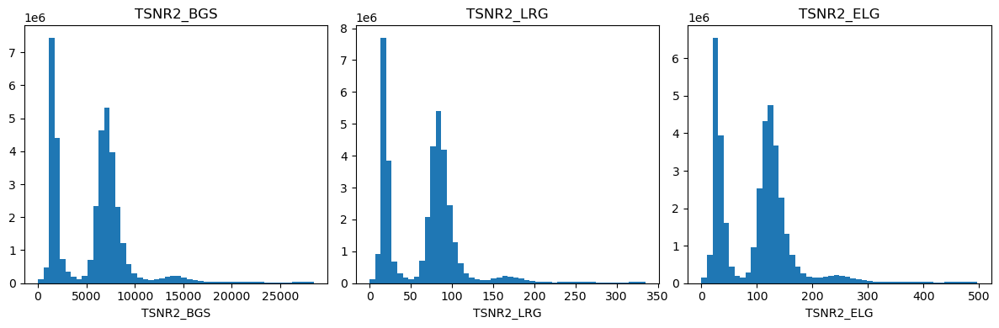

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.hist(loa_metadata["TSNR2_BGS"], bins=50, range=(0, np.percentile(loa_metadata["TSNR2_BGS"], 99)))
plt.title("TSNR2_BGS")
plt.xlabel("TSNR2_BGS")

plt.subplot(1,3,2)
plt.hist(loa_metadata["TSNR2_LRG"], bins=50, range=(0, np.percentile(loa_metadata["TSNR2_LRG"], 99)))
plt.title("TSNR2_LRG")
plt.xlabel("TSNR2_LRG")

plt.subplot(1,3,3)
plt.hist(loa_metadata["TSNR2_ELG"], bins=50, range=(0, np.percentile(loa_metadata["TSNR2_ELG"], 99)))
plt.title("TSNR2_ELG")
plt.xlabel("TSNR2_ELG")

plt.tight_layout()
plt.show()


In [8]:
#random sample galaxies 

N = min(100_000, len(galaxies))
rng = np.random.default_rng(42)
rows = rng.choice(len(galaxies), size=N, replace=False)
sampled_galaxies = galaxies[rows]

print(f"Sampled galaxies total: {len(sampled_galaxies)}")

Sampled galaxies total: 100000


In [9]:
sampled_galaxy_df = sampled_galaxies.to_pandas()
sampled_galaxy_df = sampled_galaxy_df.drop_duplicates()
COADD_OUTDIR = "/global/cfs/cdirs/m4237/zixinq/data/qa"
os.makedirs(COADD_OUTDIR, exist_ok=True)
sampled_galaxy_df.to_csv("/global/cfs/cdirs/m4237/zixinq/data/qa/galaxy_catalog.csv", index=False)
print("Saved galaxy_catalog_new.csv.")

Saved galaxy_catalog_new.csv.


In [10]:
import numpy as np

mask = (
    (loa_metadata["SPECTYPE"] == "QSO") &
    (loa_metadata["ZWARN"] == 0) &
    (loa_metadata["Z"] >= 0) & (loa_metadata["Z"] <= 0.7) &
    (loa_metadata["COADD_FIBERSTATUS"] == 0)
)
qso = loa_metadata[mask]
print(f"Total clean qso: {len(qso):,}")

Total clean qso: 268,758


In [14]:
sampled_qso

TARGETID,SURVEY,PROGRAM,HEALPIX,TILEID_LIST,RA,DEC,COADD_FIBERSTATUS,CMX_TARGET,DESI_TARGET,BGS_TARGET,MWS_TARGET,SCND_TARGET,SV1_DESI_TARGET,SV1_BGS_TARGET,SV1_MWS_TARGET,SV2_DESI_TARGET,SV2_BGS_TARGET,SV2_MWS_TARGET,SV3_DESI_TARGET,SV3_BGS_TARGET,SV3_MWS_TARGET,SV1_SCND_TARGET,SV2_SCND_TARGET,SV3_SCND_TARGET,Z,ZWARN,DELTACHI2,SPECTYPE,SUBTYPE,Z_RR,ZWARN_RR,TSNR2_BGS,TSNR2_LRG,TSNR2_ELG,TSNR2_QSO,TSNR2_LYA,PHOTSYS,LS_ID,FIBERFLUX_G,FIBERFLUX_R,FIBERFLUX_Z,FIBERTOTFLUX_G,FIBERTOTFLUX_R,FIBERTOTFLUX_Z,FLUX_G,FLUX_R,FLUX_Z,FLUX_W1,FLUX_W2,FLUX_W3,FLUX_W4,FLUX_IVAR_G,FLUX_IVAR_R,FLUX_IVAR_Z,FLUX_IVAR_W1,FLUX_IVAR_W2,FLUX_IVAR_W3,FLUX_IVAR_W4,EBV,MW_TRANSMISSION_G,MW_TRANSMISSION_R,MW_TRANSMISSION_Z,MW_TRANSMISSION_W1,MW_TRANSMISSION_W2,MW_TRANSMISSION_W3,MW_TRANSMISSION_W4
int64,str7,str6,int32,str365,float64,float64,int32,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,int64,float64,int64,float64,str6,str20,float64,int64,float32,float32,float32,float32,float32,str1,int64,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float32,float64,float32,float32,float32,float32,float32,float32,float32
39628262380409299,main,bright,8960,21776,224.57869864090202,19.990102355954374,0,--,1152921504606846976,262148,0,0,--,--,--,--,--,--,--,--,--,--,--,--,0.1699435812951058,0,56462.772291556,QSO,LOZ,0.1699435812951058,0,1696.7932,20.597763,37.4335,8.241287,14.688261,S,9906628880568787,10.84175,25.1865,53.089943,12.2902565,27.406897,55.6603,27.575356,61.492203,124.8837,264.13675,307.37375,359.48465,1355.1548,155.74866,76.08002,23.959368,1.0880718,0.34822723,0.002047499,2.6737913e-05,0.04238912097135095,0.8821419,0.91898406,0.95382065,0.992842,0.995598,0.99905956,0.99964476
39627988744012354,main,dark,12350,5774,313.81289632856226,8.201385308503063,0,--,2305843009214021637,0,1280,0,--,--,--,--,--,--,--,--,--,--,--,--,0.443508376378945,0,189146.96450519562,QSO,LOZ,0.443508376378945,0,6659.391,80.84578,113.33971,30.11908,80.78067,S,9906624604996162,43.0016,40.970604,54.860336,57.327328,49.72846,61.142063,73.618126,63.859875,78.5169,371.04163,582.09924,1497.9156,8250.446,278.24512,127.26612,77.9453,0.78393567,0.21263963,0.0008680447,1.09518805e-05,0.0971957541236387,0.75010645,0.82388645,0.8972601,0.98366314,0.98993516,0.9978449,0.9991857
39628278264234075,main,bright,4465,25204,152.76076598001245,20.789181089731688,0,--,1152921504606846976,131074,0,0,--,--,--,--,--,--,--,--,--,--,--,--,0.37747986180657106,0,3129.642582386732,QSO,LOZ,0.37747986180657106,0,1501.9458,16.444067,25.611906,5.9602633,11.204896,S,9906629128749147,2.0282283,5.9444594,12.099732,2.2086804,6.2958,12.494868,8.713659,24.83812,49.29461,102.9866,129.6308,256.00937,-7586.7007,264.39517,76.40434,15.110898,1.1589161,0.3120054,0.00057694,8.509694e-06,0.028810735395233957,0.9182987,0.94419444,0.96837616,0.99512935,0.99700594,0.9993607,0.99975854
39628341627592162,main,bright,32381,25135,264.686269534057,23.485327387726933,0,--,1152921504606846976,65537,0,0,--,--,--,--,--,--,--,--,--,--,--,--,0.2628400725328405,0,336.1087925862521,QSO,LOZ,0.2628400725328405,0,1291.7874,14.436666,26.753311,6.1159325,6.489312,S,9906630118809058,1.1217293,3.853301,7.918864,1.5417683,4.7741394,8.92774,3.0764985,9.526485,17.814726,25.320587,21.937134,146.81354,800.78674,375.1485,88.494835,28.934326,3.367859,0.98199165,0.0014168322,1.7558674e-05,0.1075117311116308,0.72756016,0.8071195,0.8869953,0.9819449,0.9888729,0.9976164,0.9990993
39628424972601781,main,bright,20282,22804,357.8772439068217,27.16079528071589,0,--,1152921504606846976,65545,0,0,--,--,--,--,--,--,--,--,--,--,--,--,0.2616010255909835,0,1540.7106970362365,QSO,LOZ,0.2616010255909835,0,2066.7092,23.581062,35.855682,9.073391,25.221102,S,9906631421069749,2.323102,6.8835196,13.76904,2.5716386,7.3713975,14.306919,4.709865,13.500455,26.202616,25.28356,27.505835,9.568626,14993.923,241.90346,106.96247,9.0333

In [18]:
sampled_qso_df = sampled_qso.to_pandas()
sampled_qso_df = sampled_qso_df.drop_duplicates()
sampled_qso_df.to_csv("/global/cfs/cdirs/m4237/zixinq/data/new/qso_catalog.csv", index=False)
print("Saved qso_catalog_new.csv.")

Saved qso_catalog_new.csv.


In [22]:
sampled_galaxies_df = sampled_galaxies.to_pandas()

sampled_galaxies_df.to_csv("/global/cfs/cdirs/m4237/zixinq/data/new/galaxy_catalog.csv", index=False)
print("Saved galaxy_catalog.csv.")

Saved galaxy_catalog.csv.


In [ ]:
#read spectra from fits files

In [2]:
from desispec.coaddition import coadd_cameras
from desispec.io import write_spectra
import os

COADD_OUTDIR = "/global/cfs/cdirs/m4237/zixinq/data"
os.makedirs(COADD_OUTDIR, exist_ok=True)

def write_coadd(spec, targetid, night, tileid=None):
    coadd_spec = coadd_cameras(spec)

    fm = coadd_spec.fibermap
    if 'TARGETID' not in fm.colnames:
        fm['TARGETID'] = [int(targetid)] * len(fm)
    if 'NIGHT' not in fm.colnames:
        fm['NIGHT'] = [int(night)] * len(fm)
    if tileid is not None and 'TILEID' not in fm.colnames:
        fm['TILEID'] = [int(tileid)] * len(fm)

    out = os.path.join(COADD_OUTDIR, f"coadd-{int(targetid)}-{night}.fits")
    write_spectra(out, coadd_spec)
    return out

In [21]:
'''
#process coadded spectra
DAILY_DIR = "/global/cfs/cdirs/desi/spectro/redux/daily"

def process_galaxy_row(row):
    results = []
    tileids = str(row["TILEID_LIST"]).replace("[","").replace("]","").replace("'","").split(',')
    for tileid in map(str.strip, tileids):
        if not tileid:
            continue
        tile_path = os.path.join(DAILY_DIR, f"tiles/cumulative/{tileid}")
        if not os.path.exists(tile_path):
            continue
        for night in os.listdir(tile_path):
            for f in glob(os.path.join(tile_path, night, "coadd-*.fits")):
                try:
                    spec = read_spectra(f, targetids=[int(row["TARGETID"])])
                    if spec is not None and getattr(spec, "num_spectra", 0) > 0:
                        coadd_path = write_coadd(spec, row["TARGETID"], night, tileid)
                        results.append((row["TARGETID"], night, coadd_path))
                        break  # only need first matching file for that night
                except Exception:
                    continue
    return results
'''

In [1]:
#process separate cameras
DAILY_DIR = "/global/cfs/cdirs/desi/spectro/redux/daily"
SAVE_BASE  = "/global/cfs/cdirs/m4237/zixinq/data/galaxy_spectra_batches"

def process_galaxy_row(row):
    results = []
    tileids = str(row["TILEID_LIST"]).replace("[", "").replace("]", "").replace("'", "").split(',')
    for tileid in tileids:
        tileid = tileid.strip()
        if not tileid:
            continue
        tile_path = os.path.join(DAILY_DIR, f"tiles/cumulative/{tileid}")
        if os.path.exists(tile_path):
            for night in os.listdir(tile_path):
                night_path = os.path.join(tile_path, night)
                file_list = glob(os.path.join(night_path, "coadd-*.fits"))
                for f in file_list:
                    try:
                        spec = read_spectra(f, targetids=row["TARGETID"])
                        if spec.fibermap is not None:
                            coadd_path = write_coadd(spec, row["TARGETID"], night, tileid)
                            results.append((row["TARGETID"], night, coadd_path))
                            break
                    except:
                        continue
    return results

In [4]:
def save_batch(batch_index, rows):
    if isinstance(rows, pd.DataFrame):
        records = rows.to_dict(orient="records")
    else:
        records = list(rows)

    with Pool(32) as pool:
        all_results = list(tqdm(pool.imap(process_galaxy_row, records), total=len(records)))

    flux_list, wave_list, ivar_list, meta_list = [], [], [], []
    for item in all_results:
        if not item:
            continue
        for targetid, night, spec in item:
            for cam in ['b', 'r', 'z']:
                try:
                    wave = spec.wave[cam]
                    flux = spec.flux[cam][0]
                    ivar = spec.ivar[cam][0]
                    wave_list.append(wave)
                    flux_list.append(flux)
                    ivar_list.append(ivar)
                    meta_list.append({'TARGETID': targetid, 'NIGHT': night, 'CAMERA': cam})
                except Exception:
                    continue

    os.makedirs(SAVE_BASE, exist_ok=True)  
    np.save(os.path.join(SAVE_BASE, f"wave_batch{batch_index}.npy"), np.array(wave_list, dtype=object))
    np.save(os.path.join(SAVE_BASE, f"flux_batch{batch_index}.npy"), np.array(flux_list, dtype=object))
    np.save(os.path.join(SAVE_BASE, f"ivar_batch{batch_index}.npy"), np.array(ivar_list, dtype=object))
    pd.DataFrame(meta_list).to_csv(os.path.join(SAVE_BASE, f"meta_batch{batch_index}.csv"), index=False)
    print(f"Batch {batch_index} saved with {len(meta_list)} spectra.")


In [22]:
batch_size = 1000
num_batches = int(np.ceil(len(galaxy_catalog) / batch_size))

for i in range(num_batches):
    start = i * batch_size
    end = min((i + 1) * batch_size, len(galaxy_catalog))
    print(f"\n--- Processing batch {i+1}/{num_batches} ---")
    save_batch(i, galaxy_catalog[start:end])


--- Processing batch 1/100 ---


  0%|          | 0/1000 [00:00<?, ?it/s]

INFO:spectra.py:451:read_spectra: iotime 0.795 sec to read spectra from:  coadd-4-4005-thru20220120.fits at 2025-09-01T16:27:56.194053
INFO:spectra.py:451:read_spectra: iotime 0.589 sec to read spectra from:  coadd-8-10086-thru20231107.fits at 2025-09-01T16:27:56.594717
INFO:spectra.py:451:read_spectra: iotime 0.917 sec to read spectra from:  coadd-0-1915-thru20210601.fits at 2025-09-01T16:27:56.661243
INFO:spectra.py:451:read_spectra: iotime 0.876 sec to read spectra from:  coadd-8-22092-thru20221116.fits at 2025-09-01T16:27:56.877696
INFO:spectra.py:451:read_spectra: iotime 0.827 sec to read spectra from:  coadd-3-21261-thru20211109.fits at 2025-09-01T16:27:56.910184
INFO:spectra.py:451:read_spectra: iotime 0.957 sec to read spectra from:  coadd-5-1413-thru20210517.fits at 2025-09-01T16:27:57.090991
INFO:spectra.py:451:read_spectra: iotime 0.784 sec to read spectra from:  coadd-5-24363-thru20220923.fits at 2025-09-01T16:27:57.138366
INFO:spectra.py:451:read_spectra: iotime 0.795 sec 

  0%|          | 1/1000 [00:03<1:03:58,  3.84s/it]

INFO:spectra.py:451:read_spectra: iotime 0.758 sec to read spectra from:  coadd-6-11502-thru20220210.fits at 2025-09-01T16:27:58.879905
INFO:spectra.py:451:read_spectra: iotime 0.768 sec to read spectra from:  coadd-7-4237-thru20220301.fits at 2025-09-01T16:27:58.866084
INFO:spectra.py:451:read_spectra: iotime 0.826 sec to read spectra from:  coadd-2-6872-thru20220420.fits at 2025-09-01T16:27:59.347833
INFO:spectra.py:451:read_spectra: iotime 0.523 sec to read spectra from:  coadd-1-24476-thru20230111.fits at 2025-09-01T16:27:59.650248
INFO:spectra.py:451:read_spectra: iotime 0.800 sec to read spectra from:  coadd-8-3926-thru20240108.fits at 2025-09-01T16:27:59.783194
INFO:spectra.py:451:read_spectra: iotime 0.665 sec to read spectra from:  coadd-0-7364-thru20220425.fits at 2025-09-01T16:27:59.959528
INFO:spectra.py:451:read_spectra: iotime 0.780 sec to read spectra from:  coadd-0-3868-thru20231008.fits at 2025-09-01T16:28:00.045402
INFO:spectra.py:451:read_spectra: iotime 0.746 sec to

...

INFO:spectra.py:451:read_spectra: iotime 0.697 sec to read spectra from:  coadd-6-7461-thru20230511.fits at 2025-09-01T19:28:06.170597
INFO:spectra.py:451:read_spectra: iotime 0.693 sec to read spectra from:  coadd-2-3635-thru20230609.fits at 2025-09-01T19:28:06.298549
INFO:spectra.py:451:read_spectra: iotime 0.686 sec to read spectra from:  coadd-5-3281-thru20231108.fits at 2025-09-01T19:28:06.480579
INFO:spectra.py:451:read_spectra: iotime 0.599 sec to read spectra from:  coadd-8-25902-thru20220218.fits at 2025-09-01T19:28:06.605720
INFO:spectra.py:451:read_spectra: iotime 0.622 sec to read spectra from:  coadd-9-25452-thru20230601.fits at 2025-09-01T19:28:06.824149
INFO:spectra.py:451:read_spectra: iotime 0.844 sec to read spectra from:  coadd-5-7877-thru20230128.fits at 2025-09-01T19:28:07.126482
INFO:spectra.py:451:read_spectra: iotime 0.778 sec to read spectra from:  coadd-8-10497-thru20220601.fits at 2025-09-01T19:28:07.215312
INFO:spectra.py:451:read_spectra: iotime 0.760 sec t

 95%|█████████▍| 948/1000 [01:38<00:06,  8.44it/s]

INFO:spectra.py:451:read_spectra: iotime 0.854 sec to read spectra from:  coadd-1-20698-thru20230108.fits at 2025-09-01T19:28:08.255586
INFO:spectra.py:451:read_spectra: iotime 0.799 sec to read spectra from:  coadd-7-2114-thru20240217.fits at 2025-09-01T19:28:08.545537
INFO:spectra.py:451:read_spectra: iotime 0.806 sec to read spectra from:  coadd-7-23777-thru20220317.fits at 2025-09-01T19:28:08.634184
INFO:spectra.py:451:read_spectra: iotime 0.789 sec to read spectra from:  coadd-5-3281-thru20231109.fits at 2025-09-01T19:28:08.789181


100%|██████████| 1000/1000 [01:41<00:00,  9.88it/s]

Batch 99 saved with 0 spectra.


In [ ]:
# get qso flux
batch_size = 1000
num_batches = int(np.ceil(len(qso_catalog) / batch_size))
for i in range(num_batches):
    start = i * batch_size
    end = min((i + 1) * batch_size, len(qso_catalog))
    print(f"\n--- Processing batch {i+1}/{num_batches} ---")
    save_batch(i, qso_catalog.iloc[start:end])   


--- Processing batch 1/20 ---


  0%|          | 0/1000 [00:00<?, ?it/s]

INFO:spectra.py:453:read_spectra: iotime 0.548 sec to read spectra from:  coadd-3-22207-thru20230111.fits at 2025-11-21T18:17:35.706461
INFO:spectra.py:453:read_spectra: iotime 0.608 sec to read spectra from:  coadd-8-3751-thru20230129.fits at 2025-11-21T18:17:35.763372
INFO:spectra.py:453:read_spectra: iotime 0.607 sec to read spectra from:  coadd-6-21061-thru20211215.fits at 2025-11-21T18:17:36.045793
INFO:spectra.py:453:read_spectra: iotime 0.775 sec to read spectra from:  coadd-0-3230-thru20231009.fits at 2025-11-21T18:17:36.135077
INFO:spectra.py:453:read_spectra: iotime 0.767 sec to read spectra from:  coadd-0-10086-thru20231107.fits at 2025-11-21T18:17:36.196567
INFO:spectra.py:453:read_spectra: iotime 0.588 sec to read spectra from:  coadd-3-23852-thru20220212.fits at 2025-11-21T18:17:36.335008
INFO:spectra.py:453:read_spectra: iotime 0.782 sec to read spectra from:  coadd-8-21451-thru20211115.fits at 2025-11-21T18:17:36.602623
INFO:spectra.py:453:read_spectra: iotime 0.878 sec

  0%|          | 1/1000 [00:02<44:54,  2.70s/it]

INFO:spectra.py:453:read_spectra: iotime 0.681 sec to read spectra from:  coadd-8-10697-thru20230618.fits at 2025-11-21T18:17:37.112251
INFO:spectra.py:453:read_spectra: iotime 1.051 sec to read spectra from:  coadd-9-3651-thru20230421.fits at 2025-11-21T18:17:37.131335
INFO:spectra.py:453:read_spectra: iotime 0.763 sec to read spectra from:  coadd-3-5774-thru20220609.fits at 2025-11-21T18:17:37.135794
INFO:spectra.py:453:read_spectra: iotime 0.904 sec to read spectra from:  coadd-3-21451-thru20211115.fits at 2025-11-21T18:17:37.317217
INFO:spectra.py:453:read_spectra: iotime 0.828 sec to read spectra from:  coadd-0-3556-thru20230918.fits at 2025-11-21T18:17:37.283946
INFO:spectra.py:453:read_spectra: iotime 0.810 sec to read spectra from:  coadd-2-25003-thru20230526.fits at 2025-11-21T18:17:37.555693
INFO:spectra.py:453:read_spectra: iotime 0.683 sec to read spectra from:  coadd-2-21481-thru20231008.fits at 2025-11-21T18:17:37.559800
INFO:spectra.py:453:read_spectra: iotime 0.947 sec 

...

INFO:spectra.py:453:read_spectra: iotime 0.821 sec to read spectra from:  coadd-1-83412-thru20231008.fits at 2025-11-21T19:18:45.454798
INFO:spectra.py:453:read_spectra: iotime 0.772 sec to read spectra from:  coadd-4-8510-thru20221021.fits at 2025-11-21T19:18:45.621138
INFO:spectra.py:453:read_spectra: iotime 0.893 sec to read spectra from:  coadd-7-8029-thru20230228.fits at 2025-11-21T19:18:45.684269
INFO:spectra.py:453:read_spectra: iotime 0.788 sec to read spectra from:  coadd-0-3528-thru20240213.fits at 2025-11-21T19:18:45.957359
INFO:spectra.py:453:read_spectra: iotime 0.818 sec to read spectra from:  coadd-2-2061-thru20211009.fits at 2025-11-21T19:18:46.135049
INFO:spectra.py:453:read_spectra: iotime 0.711 sec to read spectra from:  coadd-4-5199-thru20230328.fits at 2025-11-21T19:18:46.409811
INFO:spectra.py:453:read_spectra: iotime 0.833 sec to read spectra from:  coadd-2-24476-thru20230207.fits at 2025-11-21T19:18:46.466918
INFO:spectra.py:453:read_spectra: iotime 0.511 sec to

 96%|█████████▌| 959/1000 [01:10<00:03, 12.38it/s]

INFO:spectra.py:453:read_spectra: iotime 0.703 sec to read spectra from:  coadd-2-24037-thru20220503.fits at 2025-11-21T19:18:49.791689


100%|██████████| 1000/1000 [01:10<00:00, 14.12it/s]


INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.102 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.089 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.088 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.090 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.089 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.093 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.088 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.093 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.089 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.088 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.090 [sec]
INFO:coaddition.py:10

In [ ]:
# get coadd flux
batch_size = 1000
num_batches = int(np.ceil(len(galaxy_catalog) / batch_size))
for i in range(num_batches):
    start = i * batch_size
    end = min((i + 1) * batch_size, len(galaxy_catalog))
    print(f"\n--- Processing batch {i+1}/{num_batches} ---")
    save_batch(i, galaxy_catalog.iloc[start:end])   


--- Processing batch 1/100 ---


  0%|          | 0/1000 [00:00<?, ?it/s]

INFO:spectra.py:453:read_spectra: iotime 0.802 sec to read spectra from:  coadd-7-4981-thru20231107.fits at 2025-11-18T11:59:27.189505
INFO:spectra.py:453:read_spectra: iotime 0.801 sec to read spectra from:  coadd-8-23585-thru20220212.fits at 2025-11-18T11:59:27.478352
INFO:spectra.py:453:read_spectra: iotime 0.825 sec to read spectra from:  coadd-1-24814-thru20220419.fits at 2025-11-18T11:59:27.485729
INFO:spectra.py:453:read_spectra: iotime 0.658 sec to read spectra from:  coadd-9-26166-thru20211114.fits at 2025-11-18T11:59:27.621190
INFO:spectra.py:453:read_spectra: iotime 0.781 sec to read spectra from:  coadd-1-25476-thru20220513.fits at 2025-11-18T11:59:27.733930
INFO:spectra.py:453:read_spectra: iotime 0.672 sec to read spectra from:  coadd-4-25301-thru20220414.fits at 2025-11-18T11:59:27.933545
INFO:spectra.py:453:read_spectra: iotime 0.606 sec to read spectra from:  coadd-7-11896-thru20211001.fits at 2025-11-18T11:59:27.951301
INFO:spectra.py:453:read_spectra: iotime 0.793 se

  0%|          | 1/1000 [00:03<52:50,  3.17s/it]

INFO:spectra.py:453:read_spectra: iotime 0.954 sec to read spectra from:  coadd-4-3975-thru20221125.fits at 2025-11-18T11:59:29.491655
INFO:spectra.py:453:read_spectra: iotime 0.724 sec to read spectra from:  coadd-7-20447-thru20220212.fits at 2025-11-18T11:59:29.498207
INFO:spectra.py:453:read_spectra: iotime 0.786 sec to read spectra from:  coadd-3-24671-thru20220212.fits at 2025-11-18T11:59:29.524693
INFO:spectra.py:453:read_spectra: iotime 0.826 sec to read spectra from:  coadd-5-9264-thru20220112.fits at 2025-11-18T11:59:29.640423
INFO:spectra.py:453:read_spectra: iotime 0.818 sec to read spectra from:  coadd-3-23133-thru20220120.fits at 2025-11-18T11:59:29.821691


...

 28%|██▊       | 282/1000 [00:20<00:58, 12.29it/s]

INFO:spectra.py:453:read_spectra: iotime 0.572 sec to read spectra from:  coadd-7-20425-thru20210522.fits at 2025-11-18T15:19:56.165341
INFO:spectra.py:453:read_spectra: iotime 0.806 sec to read spectra from:  coadd-7-10238-thru20231208.fits at 2025-11-18T15:19:56.178343
INFO:spectra.py:453:read_spectra: iotime 0.277 sec to read spectra from:  coadd-6-20937-thru20231029.fits at 2025-11-18T15:19:56.230315
INFO:spectra.py:453:read_spectra: iotime 0.755 sec to read spectra from:  coadd-3-3832-thru20211102.fits at 2025-11-18T15:19:56.262795
INFO:spectra.py:453:read_spectra: iotime 0.865 sec to read spectra from:  coadd-6-2398-thru20221126.fits at 2025-11-18T15:19:56.265039
INFO:spectra.py:453:read_spectra: iotime 0.908 sec to read spectra from:  coadd-4-20646-thru20210519.fits at 2025-11-18T15:19:56.416514
INFO:spectra.py:453:read_spectra: iotime 0.753 sec to read spectra from:  coadd-7-3459-thru20230614.fits at 2025-11-18T15:19:56.430832
INFO:spectra.py:453:read_spectra: iotime 0.873 sec 

 34%|███▍      | 338/1000 [00:21<00:28, 23.21it/s]

INFO:spectra.py:453:read_spectra: iotime 0.933 sec to read spectra from:  coadd-8-4907-thru20230417.fits at 2025-11-18T15:19:56.527323
INFO:spectra.py:453:read_spectra: iotime 0.900 sec to read spectra from:  coadd-1-20314-thru20211015.fits at 2025-11-18T15:19:56.535005
INFO:spectra.py:453:read_spectra: iotime 0.798 sec to read spectra from:  coadd-7-20392-thru20210613.fits at 2025-11-18T15:19:56.634130
INFO:spectra.py:453:read_spectra: iotime 0.596 sec to read spectra from:  coadd-1-25849-thru20211020.fits at 2025-11-18T15:19:56.689379
INFO:spectra.py:453:read_spectra: iotime 0.775 sec to read spectra from:  coadd-6-483-thru20210504.fits at 2025-11-18T15:19:56.733038
INFO:spectra.py:453:read_spectra: iotime 0.581 sec to read spectra from:  coadd-0-80613-thru20210324.fits at 2025-11-18T15:19:56.742655
INFO:spectra.py:453:read_spectra: iotime 0.725 sec to read spectra from:  coadd-1-9597-thru20230618.fits at 2025-11-18T15:19:56.743122


 35%|███▍      | 347/1000 [00:21<00:27, 23.95it/s]

In [ ]:
#save galaxy catalog
import os
import numpy as np
import pandas as pd
from glob import glob

BATCH_DIR = "/global/cfs/cdirs/m4237/zixinq/data/qa"
MERGE_DIR = "/global/cfs/cdirs/m4237/zixinq/data/qa"
os.makedirs(MERGE_DIR, exist_ok=True)

wave_files = sorted(glob(os.path.join(BATCH_DIR, "coadd_wave_batch*.npy")))
flux_files = sorted(glob(os.path.join(BATCH_DIR, "coadd_flux_batch*.npy")))
ivar_files = sorted(glob(os.path.join(BATCH_DIR, "coadd_ivar_batch*.npy")))
meta_files = sorted(glob(os.path.join(BATCH_DIR, "coadd_meta_batch*.csv")))

def load_and_concat_npy(file_list):
    arrays = [np.load(f, allow_pickle=True) for f in file_list]
    return np.concatenate(arrays)

def load_and_concat_csv(file_list):
    frames = [pd.read_csv(f) for f in file_list]
    return pd.concat(frames, ignore_index=True)

wave_all = load_and_concat_npy(wave_files)
flux_all = load_and_concat_npy(flux_files)
ivar_all = load_and_concat_npy(ivar_files)
meta_all = load_and_concat_csv(meta_files)

np.save(os.path.join(MERGE_DIR, "galaxy_wave.npy"), wave_all)
np.save(os.path.join(MERGE_DIR, "galaxy_flux.npy"), flux_all)
np.save(os.path.join(MERGE_DIR, "galaxy_ivar.npy"), ivar_all)
meta_all.to_csv(os.path.join(MERGE_DIR, "galaxy_metadata.csv"), index=False)


print(f"Merged and saved to: {MERGE_DIR}")

In [4]:
batch_size = 1000
num_batches = int(np.ceil(len(galaxy_catalog) / batch_size))
for i in range(num_batches):
    start = i * batch_size
    end = min((i + 1) * batch_size, len(galaxy_catalog))
    print(f"\n--- Processing batch {i+1}/{num_batches} ---")
    save_batch(i, galaxy_catalog.iloc[start:end])   


--- Processing batch 1/100 ---


  0%|          | 0/1000 [00:00<?, ?it/s]

INFO:spectra.py:451:read_spectra: iotime 0.597 sec to read spectra from:  coadd-4-4005-thru20220120.fits at 2025-09-02T11:15:48.026826
INFO:spectra.py:451:read_spectra: iotime 0.930 sec to read spectra from:  coadd-1-24476-thru20230111.fits at 2025-09-02T11:15:48.352566
INFO:spectra.py:451:read_spectra: iotime 0.600 sec to read spectra from:  coadd-0-1915-thru20210601.fits at 2025-09-02T11:15:48.376102
INFO:spectra.py:451:read_spectra: iotime 0.607 sec to read spectra from:  coadd-8-10086-thru20231107.fits at 2025-09-02T11:15:48.642525
INFO:spectra.py:451:read_spectra: iotime 0.944 sec to read spectra from:  coadd-5-1413-thru20210517.fits at 2025-09-02T11:15:48.742596
INFO:spectra.py:451:read_spectra: iotime 0.822 sec to read spectra from:  coadd-8-22092-thru20221116.fits at 2025-09-02T11:15:48.871868
INFO:spectra.py:451:read_spectra: iotime 0.791 sec to read spectra from:  coadd-3-21261-thru20211109.fits at 2025-09-02T11:15:48.899547
INFO:spectra.py:451:read_spectra: iotime 0.770 sec 

  0%|          | 1/1000 [00:01<33:13,  2.00s/it]

INFO:spectra.py:451:read_spectra: iotime 0.950 sec to read spectra from:  coadd-3-21309-thru20211020.fits at 2025-09-02T11:15:49.455317
INFO:spectra.py:451:read_spectra: iotime 0.752 sec to read spectra from:  coadd-0-2174-thru20230211.fits at 2025-09-02T11:15:49.543967
INFO:spectra.py:451:read_spectra: iotime 0.585 sec to read spectra from:  coadd-4-11097-thru20211202.fits at 2025-09-02T11:15:49.549189
INFO:spectra.py:451:read_spectra: iotime 0.568 sec to read spectra from:  coadd-6-22414-thru20221115.fits at 2025-09-02T11:15:49.570077
INFO:spectra.py:451:read_spectra: iotime 0.939 sec to read spectra from:  coadd-3-3424-thru20211107.fits at 2025-09-02T11:15:49.585800
INFO:spectra.py:451:read_spectra: iotime 0.570 sec to read spectra from:  coadd-8-23268-thru20220313.fits at 2025-09-02T11:15:49.643736
INFO:spectra.py:451:read_spectra: iotime 0.877 sec to read spectra from:  coadd-0-2557-thru20211130.fits at 2025-09-02T11:15:49.730748
INFO:spectra.py:451:read_spectra: iotime 0.517 sec 

...

INFO:spectra.py:451:read_spectra: iotime 0.790 sec to read spectra from:  coadd-9-24182-thru20220102.fits at 2025-09-02T16:10:59.048029
INFO:spectra.py:451:read_spectra: iotime 0.868 sec to read spectra from:  coadd-9-24475-thru20221009.fits at 2025-09-02T16:10:59.066877
INFO:spectra.py:451:read_spectra: iotime 0.852 sec to read spectra from:  coadd-1-20698-thru20230824.fits at 2025-09-02T16:10:59.123029
INFO:spectra.py:451:read_spectra: iotime 0.899 sec to read spectra from:  coadd-4-24897-thru20230409.fits at 2025-09-02T16:10:59.303145
INFO:spectra.py:451:read_spectra: iotime 0.895 sec to read spectra from:  coadd-5-20602-thru20230304.fits at 2025-09-02T16:10:59.354562
INFO:spectra.py:451:read_spectra: iotime 0.742 sec to read spectra from:  coadd-3-10603-thru20230617.fits at 2025-09-02T16:10:59.356182
INFO:spectra.py:451:read_spectra: iotime 0.764 sec to read spectra from:  coadd-2-23399-thru20220221.fits at 2025-09-02T16:10:59.500703
INFO:spectra.py:451:read_spectra: iotime 0.543 s

 95%|█████████▍| 948/1000 [01:20<00:04, 10.92it/s]

INFO:spectra.py:451:read_spectra: iotime 0.600 sec to read spectra from:  coadd-5-3281-thru20231109.fits at 2025-09-02T16:11:02.975588


100%|██████████| 1000/1000 [01:21<00:00, 12.25it/s]


INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.108 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.107 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.101 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.094 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.094 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.092 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.094 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.091 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.090 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.092 [sec]
INFO:coaddition.py:1023:coadd_cameras: coadding spectra across cameras took: 0.094 [sec]
INFO:coaddition.py:10

In [18]:
import os
import numpy as np
import pandas as pd
from glob import glob

BATCH_DIR = "/global/cfs/cdirs/m4237/galaxy_spectra_batches"
MERGE_DIR = "/global/cfs/cdirs/m4237/galaxy_spectra_merged"
os.makedirs(MERGE_DIR, exist_ok=True)

wave_files = sorted(glob(os.path.join(BATCH_DIR, "wave_batch*.npy")))
flux_files = sorted(glob(os.path.join(BATCH_DIR, "flux_batch*.npy")))
ivar_files = sorted(glob(os.path.join(BATCH_DIR, "ivar_batch*.npy")))
meta_files = sorted(glob(os.path.join(BATCH_DIR, "meta_batch*.csv")))

def load_and_concat_npy(file_list):
    arrays = [np.load(f, allow_pickle=True) for f in file_list]
    return np.concatenate(arrays)

def load_and_concat_csv(file_list):
    frames = [pd.read_csv(f) for f in file_list]
    return pd.concat(frames, ignore_index=True)

print("Merging batches...")

wave_all = load_and_concat_npy(wave_files)
flux_all = load_and_concat_npy(flux_files)
ivar_all = load_and_concat_npy(ivar_files)
meta_all = load_and_concat_csv(meta_files)

np.save(os.path.join(MERGE_DIR, "galaxy_wave.npy"), wave_all)
np.save(os.path.join(MERGE_DIR, "galaxy_flux.npy"), flux_all)
np.save(os.path.join(MERGE_DIR, "galaxy_ivar.npy"), ivar_all)
meta_all.to_csv(os.path.rgedjoin(MERGE_DIR, "galaxy_metadata.csv"), index=False)

print(f"Merged and saved to: {MERGE_DIR}")

Merging batches...
Merged and saved to: /global/cfs/cdirs/m4237/galaxy_spectra_merged


In [4]:
import os, numpy as np, pandas as pd

GLOBAL_OUT = "/global/cfs/cdirs/m4237/zixinq/data/galaxy_spectra_dataset"
os.makedirs(GLOBAL_OUT, exist_ok=True)

# Save per-camera
np.savez_compressed(
    os.path.join(GLOBAL_OUT, "camera_spectra.npz"),
    waves=np.array(waves_all, dtype=object),
    fluxes=np.array(fluxes_all, dtype=object),
    ivars=np.array(ivars_all, dtype=object),
)
meta_all.to_csv(os.path.join(GLOBAL_OUT, "camera_meta.csv"), index=False)

# Save coadds
np.savez_compressed(
    os.path.join(GLOBAL_OUT, "coadd_spectra.npz"),
    waves=np.array(co_w_all, dtype=object),
    fluxes=np.array(co_f_all, dtype=object),
    ivars=np.array(co_i_all, dtype=object),
)
co_meta_all.to_csv(os.path.join(GLOBAL_OUT, "coadd_meta.csv"), index=False)

print("Saved NPZ + CSV to", GLOBAL_OUT)


Saved NPZ + CSV to /global/cfs/cdirs/m4237/zixinq/data/galaxy_spectra_dataset
